<a href="https://colab.research.google.com/github/Deepti154/Movie-Recommendation-System/blob/main/Movie_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving movies.csv to movies.csv


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving tags.csv to tags.csv


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ratings.csv to ratings.csv


In [ ]:
import pandas as pd
movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")
tags = pd.read_csv("tags.csv")
print("Movies")
print(movies.head())
print("\nRatings")
print(ratings.head())
print("\nTags")
print(tags.head())

Movies
   movieId         title                      genres
0        1     Toy Story     Animation|Comedy|Family
1        2  Finding Nemo  Animation|Adventure|Family
2        3  Monsters Inc     Animation|Comedy|Family
3        4         Shrek    Animation|Comedy|Fantasy
4        5       Ice Age  Animation|Adventure|Comedy

Ratings
   userId  movieId  rating
0       1        1     4.5
1       2        1     4.0
2       3        1     5.0
3       4        2     4.8
4       5        2     4.6

Tags
   userId  movieId    tag
0       1        1  funny
1       2        1   kids
2       3        1   toys
3       4        2   fish
4       5        2  ocean


In [ ]:
movies["genres_clean"] = (
movies["genres"]
.str.replace("|", " ", regex=False)
.str.lower()
)
movies.head()

,movieId,title,genres,genres_clean
0,1,Toy Story,Animation|Comedy|Family,animation comedy family
1,2,Finding Nemo,Animation|Adventure|Family,animation adventure family
2,3,Monsters Inc,Animation|Comedy|Family,animation comedy family
3,4,Shrek,Animation|Comedy|Fantasy,animation comedy fantasy
4,5,Ice Age,Animation|Adventure|Comedy,animation adventure comedy


In [ ]:
tag_text = tags.groupby("movieId")["tag"].apply(
lambda x: " ".join(x.astype(str)).lower()
)
tag_text.head()

,tag
movieId,
1,funny kids toys
2,fish ocean adventure
3,monsters family
4,ogre fairy tale
5,ice animals


In [ ]:
df = movies.merge(
tag_text,
on="movieId",
how="left"
)
df["tag"] = df["tag"].fillna("")

In [ ]:
df.head()

,movieId,title,genres,genres_clean,tag
0,1,Toy Story,Animation|Comedy|Family,animation comedy family,funny kids toys
1,2,Finding Nemo,Animation|Adventure|Family,animation adventure family,fish ocean adventure
2,3,Monsters Inc,Animation|Comedy|Family,animation comedy family,monsters family
3,4,Shrek,Animation|Comedy|Fantasy,animation comedy fantasy,ogre fairy tale
4,5,Ice Age,Animation|Adventure|Comedy,animation adventure comedy,ice animals


In [ ]:
df["soup"] = (
df["genres_clean"] +
" " +
df["tag"]
)

In [ ]:
print(df[["title","soup"]].head())


          title                                             soup
0     Toy Story          animation comedy family funny kids toys
1  Finding Nemo  animation adventure family fish ocean adventure
2  Monsters Inc          animation comedy family monsters family
3         Shrek         animation comedy fantasy ogre fairy tale
4       Ice Age           animation adventure comedy ice animals


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
stop_words="english"
)
X = tfidf.fit_transform(df["soup"])
print(X.shape)

(20, 54)


In [ ]:
from sklearn.metrics.pairwise import linear_kernel
similarity = linear_kernel(
X,
X
)
print(similarity.shape)

(20, 20)


In [ ]:
indices = pd.Series(
df.index,
index=df["title"].str.lower()
)
print(indices)

title
toy story               0
finding nemo            1
monsters inc            2
shrek                   3
ice age                 4
the avengers            5
iron man                6
captain america         7
thor                    8
doctor strange          9
titanic                10
the notebook           11
a walk to remember     12
la la land             13
pride and prejudice    14
the conjuring          15
insidious              16
annabelle              17
the nun                18
it                     19
dtype: int64


In [ ]:
indices = pd.Series(
df.index,
index=df["title"].str.lower()
)

In [ ]:
def recommend(movie_name, n=5):

    idx = indices[movie_name.lower()]

    scores = list(
        enumerate(similarity[idx])
    )

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = scores[1:n+1]

    movie_indices = [
        i[0] for i in scores
    ]

    return df.iloc[
        movie_indices
    ][["title", "genres"]]

In [ ]:
recommend("toy story")

,title,genres
2,Monsters Inc,Animation|Comedy|Family
4,Ice Age,Animation|Adventure|Comedy
1,Finding Nemo,Animation|Adventure|Family
3,Shrek,Animation|Comedy|Fantasy
5,The Avengers,Action|Adventure|Sci-Fi


In [ ]:
recommend('iron man')

,title,genres
5,The Avengers,Action|Adventure|Sci-Fi
7,Captain America,Action|Adventure|Sci-Fi
9,Doctor Strange,Action|Fantasy|Sci-Fi
8,Thor,Action|Fantasy|Adventure
1,Finding Nemo,Animation|Adventure|Family


In [ ]:
top_movies = ratings.groupby(
"movieId"
)["rating"].mean().reset_index()

top_movies.columns = [
"movieId",
"avg_rating"
]

top_movies = top_movies.merge(
movies,
on="movieId"
)

top_movies.sort_values(
"avg_rating",
ascending=False
).head(10)

,movieId,avg_rating,title,genres,genres_clean
10,11,5.0,Titanic,Romance|Drama,romance drama
5,6,5.0,The Avengers,Action|Adventure|Sci-Fi,action adventure sci-fi
14,15,4.8,Pride And Prejudice,Romance|Drama,romance drama
6,7,4.8,Iron Man,Action|Adventure|Sci-Fi,action adventure sci-fi
9,10,4.7,Doctor Strange,Action|Fantasy|Sci-Fi,action fantasy sci-fi
1,2,4.7,Finding Nemo,Animation|Adventure|Family,animation adventure family
13,14,4.6,La La Land,Romance|Musical|Drama,romance musical drama
7,8,4.6,Captain America,Action|Adventure|Sci-Fi,action adventure sci-fi
0,1,4.5,Toy Story,Animation|Comedy|Family,animation comedy family
11,12,4.5,The Notebook,Romance|Drama,romance drama


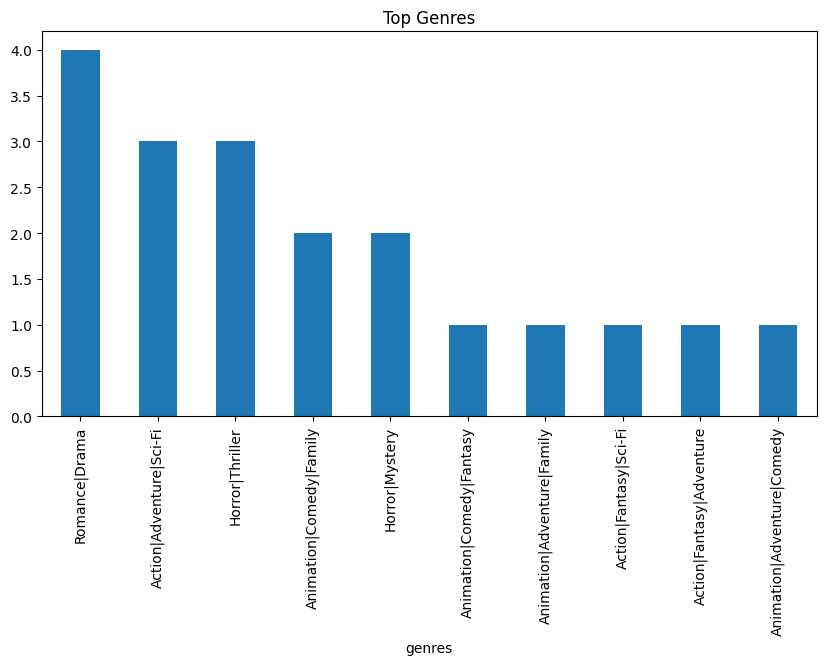

In [ ]:
import matplotlib.pyplot as plt

genre_count = movies["genres"].value_counts()

plt.figure(figsize=(10,5))
genre_count.head(10).plot(
kind="bar"
)
plt.title("Top Genres")
plt.show()

In [ ]:
%%writefile app.py
import streamlit as st

st.title(
    "Movie Recommendation System"
)

movie = st.text_input(
    "Enter Movie Name"
)

if st.button("Recommend"):
    st.write(
        recommend(movie)
    )

Writing app.py


In [ ]:
!ls

app.py	movies.csv  ratings.csv  sample_data  tags.csv


In [ ]:
!cat app.py

import streamlit as st

st.title(
    "Movie Recommendation System"
)

movie = st.text_input(
    "Enter Movie Name"
)

if st.button("Recommend"):
    st.write(
        recommend(movie)
    )


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 24.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
recommend("iron man")

,title,genres
5,The Avengers,Action|Adventure|Sci-Fi
7,Captain America,Action|Adventure|Sci-Fi
9,Doctor Strange,Action|Fantasy|Sci-Fi
8,Thor,Action|Fantasy|Adventure
1,Finding Nemo,Animation|Adventure|Family
